## <span style="color:#1F4E79;">**CDM-Generated Choice Data Fitted with a BTL Model**</span>


This notebook studies model misspecification by generating synthetic
choice observations from a full Context-Dependent Model and fitting a
Bradley--Terry/Luce model to the same data.

The main objective is to determine when a context-independent BTL model
fails to represent choices generated by context-dependent preferences.

In [1]:
# Import libraries and reusable CDM and BTL functions used in this experiment.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from bradley_terry import *
from context_dependent_model import *

In [2]:
# Create the output directory for CDM-to-BTL figures used in the thesis.
PROJECT_ROOT = next(
    directory
    for directory in (
        Path.cwd(),
        *Path.cwd().parents,
    )
    if (directory / "pyproject.toml").exists()
)
CDM_BTL_FIGURE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "images"
    / "experiments"
    / "context_dependent_model"
    / "cdm_btl"
)

CDM_BTL_FIGURE_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

CDM_BTL_FIGURE_DIRECTORY

PosixPath('/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/context_dependent_model/cdm_btl')

In [3]:
SEED = 20260831

NUMBER_OF_ITEMS = 5
NUMBER_OF_OBSERVATIONS = 1_000
CHOICE_SET_SIZES = (2, 3)

TRAIN_FRACTION = 0.8
PARAMETER_SCALE = 0.5

DEVICE = torch.device("cpu")
DTYPE = torch.float64

np.random.seed(SEED)
torch.manual_seed(SEED)
experiment_settings = pd.DataFrame(
    {
        "Setting": [
            "Random seed",
            "Number of items",
            "Number of observations",
            "Choice-set sizes",
            "Training fraction",
            "Parameter scale",
            "PyTorch device",
            "PyTorch dtype",
        ],
        "Value": [
            SEED,
            NUMBER_OF_ITEMS,
            NUMBER_OF_OBSERVATIONS,
            CHOICE_SET_SIZES,
            TRAIN_FRACTION,
            PARAMETER_SCALE,
            DEVICE,
            DTYPE,
        ],
    }
)

experiment_settings

,Setting,Value
0,Random seed,20260831
1,Number of items,5
2,Number of observations,1000
3,Choice-set sizes,"(2, 3)"
4,Training fraction,0.8
5,Parameter scale,0.5
6,PyTorch device,cpu
7,PyTorch dtype,torch.float64


## 2. Generate Choice Data from the Full CDM

In [4]:
# Generate true full-CDM parameters and synthetic choice observations.

true_interactions = generate_cdm_parameters(
    number_of_items=NUMBER_OF_ITEMS,
    parameter_scale=PARAMETER_SCALE,
    random_seed=SEED,
    device=DEVICE,
    dtype=DTYPE,
)

cdm_data = generate_cdm_choice_data(
    interaction_matrix=true_interactions,
    number_of_observations=NUMBER_OF_OBSERVATIONS,
    choice_set_sizes=CHOICE_SET_SIZES,
    random_seed=SEED,
)

In [5]:
# Remove padded entries using the choice mask and create explicit choice observations.

choice_observations = [
    (
        int(chosen_item.item()),
        tuple(
            int(item)
            for item in choice_set[
                choice_mask
            ].detach().cpu().tolist()
        ),
    )
    for choice_set, choice_mask, chosen_item in zip(
        cdm_data.choice_sets,
        cdm_data.choice_mask,
        cdm_data.chosen_items,
    )
]

In [6]:
# Verify the actual choice-set sizes after removing padded entries.

choice_set_size_check = pd.Series(
    [
        len(choice_set)
        for _, choice_set in choice_observations
    ]
).value_counts().sort_index()

print(choice_set_size_check)

print(
    "Contains padding:",
    any(
        -1 in choice_set
        for _, choice_set in choice_observations
    ),
)

2    485
3    515
Name: count, dtype: int64
Contains padding: False


In [7]:
print(type(cdm_data))
print(dir(cdm_data))

<class 'context_dependent_model.simulation.CDMChoiceData'>
['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'choice_mask', 'choice_sets', 'chosen_items', 'chosen_positions']


In [8]:
# Display the first ten generated choice observations.

choice_observation_preview = pd.DataFrame(
    [
        {
            "Observation": observation_number,
            "Chosen item": chosen_item,
            "Choice set": choice_set,
            "Choice-set size": len(choice_set),
        }
        for observation_number, (
            chosen_item,
            choice_set,
        ) in enumerate(
            choice_observations[:10],
            start=1,
        )
    ]
)

choice_observation_preview

,Observation,Chosen item,Choice set,Choice-set size
0,1,1,"(1, 0, 2)",3
1,2,0,"(2, 0)",2
2,3,4,"(3, 4)",2
3,4,2,"(3, 4, 2)",3
4,5,3,"(3, 0, 2)",3
5,6,2,"(3, 2)",2
6,7,1,"(1, 0)",2
7,8,1,"(1, 3)",2
8,9,4,"(4, 3, 1)",3
9,10,1,"(2, 4, 1)",3


In [9]:
# Summarise the generated interaction matrix and choice observations.

choice_set_size_counts = pd.Series(
    [
        len(choice_set)
        for _, choice_set in choice_observations
    ]
).value_counts()

generation_summary = pd.DataFrame(
    {
        "Quantity": [
            "Interaction-matrix shape",
            "Number of observations",
            "Two-item observations",
            "Three-item observations",
            "Smallest chosen-item index",
            "Largest chosen-item index",
            "Sum of interaction parameters",
        ],
        "Value": [
            tuple(true_interactions.shape),
            len(choice_observations),
            int(choice_set_size_counts.get(2, 0)),
            int(choice_set_size_counts.get(3, 0)),
            min(
                chosen_item
                for chosen_item, _ in choice_observations
            ),
            max(
                chosen_item
                for chosen_item, _ in choice_observations
            ),
            true_interactions.sum().item(),
        ],
    }
)

generation_summary

,Quantity,Value
0,Interaction-matrix shape,"(5, 5)"
1,Number of observations,1000
2,Two-item observations,485
3,Three-item observations,515
4,Smallest chosen-item index,0
5,Largest chosen-item index,4
6,Sum of interaction parameters,0.0


In [10]:
# Count how often each item appears and how often it is chosen.

item_appearance_counts = np.zeros(
    NUMBER_OF_ITEMS,
    dtype=int,
)

item_choice_counts = np.zeros(
    NUMBER_OF_ITEMS,
    dtype=int,
)

for chosen_item, choice_set in choice_observations:
    item_appearance_counts[list(choice_set)] += 1
    item_choice_counts[chosen_item] += 1

item_appearance_summary = pd.DataFrame(
    {
        "Item": np.arange(NUMBER_OF_ITEMS),
        "Number of appearances": item_appearance_counts,
        "Number of times chosen": item_choice_counts,
        "Empirical choice rate": (
            item_choice_counts
            / item_appearance_counts
        ),
    }
)

item_appearance_summary.style.format(
    {
        "Empirical choice rate": "{:.4f}",
    }
)

,Item,Number of appearances,Number of times chosen,Empirical choice rate
0,0,510,120,0.2353
1,1,497,242,0.4869
2,2,506,226,0.4466
3,3,493,153,0.3103
4,4,509,259,0.5088


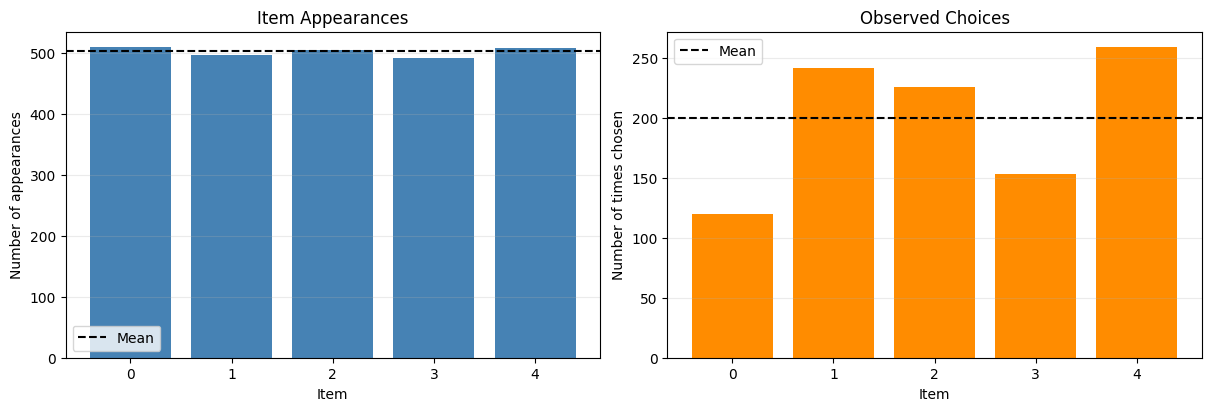

In [11]:
# Plot item appearance and choice counts to inspect sampling coverage.

items = np.arange(NUMBER_OF_ITEMS)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
    constrained_layout=True,
)

axes[0].bar(
    items,
    item_appearance_counts,
    color="steelblue",
)

axes[0].axhline(
    item_appearance_counts.mean(),
    color="black",
    linestyle="--",
    label="Mean",
)

axes[0].set_title("Item Appearances")
axes[0].set_xlabel("Item")
axes[0].set_ylabel("Number of appearances")
axes[0].set_xticks(items)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    items,
    item_choice_counts,
    color="darkorange",
)

axes[1].axhline(
    item_choice_counts.mean(),
    color="black",
    linestyle="--",
    label="Mean",
)

axes[1].set_title("Observed Choices")
axes[1].set_xlabel("Item")
axes[1].set_ylabel("Number of times chosen")
axes[1].set_xticks(items)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.show()

### training and test split

In [12]:
# Split the CDM-generated observations reproducibly into training and test sets.

split_random_generator = np.random.default_rng(
    SEED + 1
)

shuffled_indices = split_random_generator.permutation(
    len(choice_observations)
)

number_of_training_observations = int(
    TRAIN_FRACTION
    * len(choice_observations)
)

training_indices = shuffled_indices[
    :number_of_training_observations
]

test_indices = shuffled_indices[
    number_of_training_observations:
]

training_observations = [
    choice_observations[index]
    for index in training_indices
]

test_observations = [
    choice_observations[index]
    for index in test_indices
]

In [13]:
# Summarise the number and choice-set sizes of the training and test observations.

split_summary = pd.DataFrame(
    {
        "Dataset": [
            "Complete",
            "Training",
            "Test",
        ],
        "Number of observations": [
            len(choice_observations),
            len(training_observations),
            len(test_observations),
        ],
        "Two-item observations": [
            sum(
                len(choice_set) == 2
                for _, choice_set in choice_observations
            ),
            sum(
                len(choice_set) == 2
                for _, choice_set in training_observations
            ),
            sum(
                len(choice_set) == 2
                for _, choice_set in test_observations
            ),
        ],
        "Three-item observations": [
            sum(
                len(choice_set) == 3
                for _, choice_set in choice_observations
            ),
            sum(
                len(choice_set) == 3
                for _, choice_set in training_observations
            ),
            sum(
                len(choice_set) == 3
                for _, choice_set in test_observations
            ),
        ],
    }
)

split_summary

,Dataset,Number of observations,Two-item observations,Three-item observations
0,Complete,1000,485,515
1,Training,800,379,421
2,Test,200,106,94


## 4. Fit the Context-Independent BTL/Luce Model


In [14]:
# Estimate context-independent item parameters from the CDM-generated training data.

estimated_btl_parameters = (
    estimate_top1_parameters_with_choix(
        number_of_items=NUMBER_OF_ITEMS,
        observations=training_observations,
        alpha=0.0,
        maximum_iterations=1_000,
        tolerance=1e-8,
    )
)

In [15]:
# Display the estimated context-independent parameter for each item.

estimated_btl_parameter_table = pd.DataFrame(
    {
        "Item": np.arange(NUMBER_OF_ITEMS),
        "Estimated BTL/Luce parameter": (
            estimated_btl_parameters
        ),
    }
)

estimated_btl_parameter_table.style.format(
    {
        "Estimated BTL/Luce parameter": "{:.4f}",
    }
)

,Item,Estimated BTL/Luce parameter
0,0,-0.6048
1,1,0.3590
2,2,0.2224
3,3,-0.3272
4,4,0.3505


In [16]:
# Evaluate the uniform baseline and fitted BTL/Luce model using average NLL.

uniform_btl_parameters = np.zeros(
    NUMBER_OF_ITEMS
)

uniform_training_nll = (
    average_top1_negative_log_likelihood(
        observations=training_observations,
        parameters=uniform_btl_parameters,
    )
)

estimated_training_nll = (
    average_top1_negative_log_likelihood(
        observations=training_observations,
        parameters=estimated_btl_parameters,
    )
)

uniform_test_nll = (
    average_top1_negative_log_likelihood(
        observations=test_observations,
        parameters=uniform_btl_parameters,
    )
)

estimated_test_nll = (
    average_top1_negative_log_likelihood(
        observations=test_observations,
        parameters=estimated_btl_parameters,
    )
)

In [17]:
# Summarise the training and test NLL of the uniform and fitted models.

btl_nll_summary = pd.DataFrame(
    {
        "Model": [
            "Uniform baseline",
            "Estimated BTL/Luce",
        ],
        "Training NLL": [
            uniform_training_nll,
            estimated_training_nll,
        ],
        "Test NLL": [
            uniform_test_nll,
            estimated_test_nll,
        ],
    }
)

btl_nll_summary.style.format(
    {
        "Training NLL": "{:.4f}",
        "Test NLL": "{:.4f}",
    }
)

,Model,Training NLL,Test NLL
0,Uniform baseline,0.9065,0.8837
1,Estimated BTL/Luce,0.8556,0.8392


In [18]:
# Check how many generated observations contain two and three items.

pd.Series(
    [
        len(choice_set)
        for _, choice_set in choice_observations
    ]
).value_counts().sort_index()

2    485
3    515
Name: count, dtype: int64

## 
 Compare the BTL/Luce Model with the True CDM


In [19]:
# Convert the saved training and test indices into PyTorch index tensors.

training_index_tensor = torch.as_tensor(
    training_indices,
    dtype=torch.long,
    device=cdm_data.choice_sets.device,
)

test_index_tensor = torch.as_tensor(
    test_indices,
    dtype=torch.long,
    device=cdm_data.choice_sets.device,
)

In [20]:
# Construct CDMChoiceData objects using the same training and test observations.

training_cdm_data = type(cdm_data)(
    choice_sets=cdm_data.choice_sets[
        training_index_tensor
    ],
    choice_mask=cdm_data.choice_mask[
        training_index_tensor
    ],
    chosen_positions=cdm_data.chosen_positions[
        training_index_tensor
    ],
)

test_cdm_data = type(cdm_data)(
    choice_sets=cdm_data.choice_sets[
        test_index_tensor
    ],
    choice_mask=cdm_data.choice_mask[
        test_index_tensor
    ],
    chosen_positions=cdm_data.chosen_positions[
        test_index_tensor
    ],
)

In [21]:
# Verify that both representations contain the same training and test sizes.

split_alignment_summary = pd.DataFrame(
    {
        "Dataset": [
            "Training",
            "Test",
        ],
        "Choice observations": [
            len(training_observations),
            len(test_observations),
        ],
        "CDM data rows": [
            len(training_cdm_data.chosen_items),
            len(test_cdm_data.chosen_items),
        ],
    }
)

split_alignment_summary

,Dataset,Choice observations,CDM data rows
0,Training,800,800
1,Test,200,200


In [22]:
# Display the CDM NLL function signature before using it.

import inspect

print(
    inspect.signature(
        average_cdm_negative_log_likelihood
    )
)

(interaction_matrix: 'torch.Tensor', choice_sets: 'torch.Tensor', chosen_positions: 'torch.Tensor', choice_mask: 'torch.Tensor | None' = None) -> 'torch.Tensor'


In [23]:
# Evaluate the true full CDM on the training and test observations.

true_cdm_training_nll = float(
    average_cdm_negative_log_likelihood(
        interaction_matrix=true_interactions,
        choice_sets=training_cdm_data.choice_sets,
        chosen_positions=training_cdm_data.chosen_positions,
        choice_mask=training_cdm_data.choice_mask,
    ).item()
)

true_cdm_test_nll = float(
    average_cdm_negative_log_likelihood(
        interaction_matrix=true_interactions,
        choice_sets=test_cdm_data.choice_sets,
        chosen_positions=test_cdm_data.chosen_positions,
        choice_mask=test_cdm_data.choice_mask,
    ).item()
)

In [24]:
# Compare the uniform baseline, true CDM, and estimated BTL/Luce model.

model_comparison = pd.DataFrame(
    {
        "Model": [
            "Uniform baseline",
            "True full CDM",
            "Estimated BTL/Luce",
        ],
        "Training NLL": [
            uniform_training_nll,
            true_cdm_training_nll,
            estimated_training_nll,
        ],
        "Test NLL": [
            uniform_test_nll,
            true_cdm_test_nll,
            estimated_test_nll,
        ],
    }
)

model_comparison.style.format(
    {
        "Training NLL": "{:.4f}",
        "Test NLL": "{:.4f}",
    }
)

,Model,Training NLL,Test NLL
0,Uniform baseline,0.9065,0.8837
1,True full CDM,0.8001,0.7602
2,Estimated BTL/Luce,0.8556,0.8392


### BTL/Luce Misspecification Gap


In [25]:
# Calculate the additional NLL caused by fitting BTL/Luce to CDM-generated data.

training_misspecification_gap = (
    estimated_training_nll
    - true_cdm_training_nll
)

test_misspecification_gap = (
    estimated_test_nll
    - true_cdm_test_nll
)

misspecification_summary = pd.DataFrame(
    {
        "Dataset": [
            "Training",
            "Test",
        ],
        "BTL/Luce NLL": [
            estimated_training_nll,
            estimated_test_nll,
        ],
        "True CDM NLL": [
            true_cdm_training_nll,
            true_cdm_test_nll,
        ],
        "Misspecification gap": [
            training_misspecification_gap,
            test_misspecification_gap,
        ],
    }
)

misspecification_summary.style.format(
    {
        "BTL/Luce NLL": "{:.4f}",
        "True CDM NLL": "{:.4f}",
        "Misspecification gap": "{:.4f}",
    }
)

,Dataset,BTL/Luce NLL,True CDM NLL,Misspecification gap
0,Training,0.8556,0.8001,0.0555
1,Test,0.8392,0.7602,0.0790


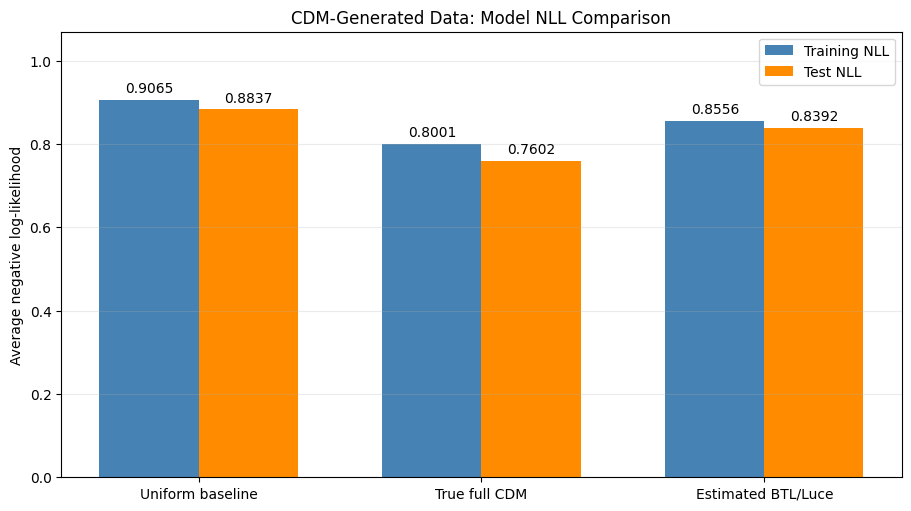

In [26]:
# Plot the training and test NLL of the three evaluated models.

model_names = model_comparison["Model"].to_numpy()
training_nll_values = model_comparison[
    "Training NLL"
].to_numpy()

test_nll_values = model_comparison[
    "Test NLL"
].to_numpy()

model_positions = np.arange(
    len(model_names)
)

bar_width = 0.35

figure, axis = plt.subplots(
    figsize=(9, 5),
    constrained_layout=True,
)

training_bars = axis.bar(
    model_positions - bar_width / 2,
    training_nll_values,
    width=bar_width,
    label="Training NLL",
    color="steelblue",
)

test_bars = axis.bar(
    model_positions + bar_width / 2,
    test_nll_values,
    width=bar_width,
    label="Test NLL",
    color="darkorange",
)

axis.bar_label(
    training_bars,
    fmt="%.4f",
    padding=3,
)

axis.bar_label(
    test_bars,
    fmt="%.4f",
    padding=3,
)

axis.set_title(
    "CDM-Generated Data: Model NLL Comparison"
)

axis.set_ylabel(
    "Average negative log-likelihood"
)

axis.set_xticks(
    model_positions,
    model_names,
)

axis.set_ylim(
    0,
    max(
        training_nll_values.max(),
        test_nll_values.max(),
    )
    * 1.18,
)

axis.legend()
axis.grid(
    axis="y",
    alpha=0.25,
)

plt.show()

### Repeated CDM-to-BTL Experiments


In [27]:
# Run one CDM-to-BTL trial to verify the complete reusable pipeline.

cdm_to_btl_smoke_test = pd.DataFrame(
    run_cdm_to_btl_experiment(
        true_interactions=true_interactions,
        observation_counts=[1_000],
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=[SEED],
        train_fraction=TRAIN_FRACTION,
        choix_alpha=0.0,
        maximum_iterations=1_000,
        tolerance=1e-8,
    )
)

cdm_to_btl_smoke_test

Running 1/1: observations=1,000, run=1
All CDM-to-BTL trials completed.


,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,Uniform test NLL,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds)
0,5,1000,1,20260831,20260832,800,200,19,4,0.8974,0.920208,0.783793,0.825542,0.84635,0.876249,0.062557,0.050707,0.05105,0.043959,0.014796


In [28]:
# Define the observation counts and independent seeds for repeated CDM-to-BTL trials.

CDM_TO_BTL_OBSERVATION_COUNTS = [
    1_000,
    5_000,
    10_000,
    50_000,
]

CDM_TO_BTL_SEEDS = [
    SEED + offset
    for offset in range(10)
]

cdm_to_btl_settings = pd.DataFrame(
    {
        "Setting": [
            "Observation counts",
            "Runs per observation count",
            "Total runs",
        ],
        "Value": [
            str(CDM_TO_BTL_OBSERVATION_COUNTS),
            len(CDM_TO_BTL_SEEDS),
            (
                len(CDM_TO_BTL_OBSERVATION_COUNTS)
                * len(CDM_TO_BTL_SEEDS)
            ),
        ],
    }
)

cdm_to_btl_settings

,Setting,Value
0,Observation counts,"[1000, 5000, 10000, 50000]"
1,Runs per observation count,10
2,Total runs,40


In [29]:
# Run repeated CDM-to-BTL experiments as the number of observations increases.

cdm_to_btl_results = pd.DataFrame(
    run_cdm_to_btl_experiment(
        true_interactions=true_interactions,
        observation_counts=(
            CDM_TO_BTL_OBSERVATION_COUNTS
        ),
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=CDM_TO_BTL_SEEDS,
        train_fraction=TRAIN_FRACTION,
        choix_alpha=0.0,
        maximum_iterations=1_000,
        tolerance=1e-8,
    )
)

cdm_to_btl_results

Running 1/40: observations=1,000, run=1
Running 2/40: observations=1,000, run=2
Running 3/40: observations=1,000, run=3
Running 4/40: observations=1,000, run=4
Running 5/40: observations=1,000, run=5
Running 6/40: observations=1,000, run=6
Running 7/40: observations=1,000, run=7
Running 8/40: observations=1,000, run=8
Running 9/40: observations=1,000, run=9
Running 10/40: observations=1,000, run=10
Running 11/40: observations=5,000, run=1
Running 12/40: observations=5,000, run=2
Running 13/40: observations=5,000, run=3
Running 14/40: observations=5,000, run=4
Running 15/40: observations=5,000, run=5
Running 16/40: observations=5,000, run=6
Running 17/40: observations=5,000, run=7
Running 18/40: observations=5,000, run=8
Running 19/40: observations=5,000, run=9
Running 20/40: observations=5,000, run=10
Running 21/40: observations=10,000, run=1
Running 22/40: observations=10,000, run=2
Running 23/40: observations=10,000, run=3
Running 24/40: observations=10,000, run=4
Running 25/40: obse

,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,Uniform test NLL,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds)
0,5,1000,1,20260831,20260832,800,200,19,4,0.897400,0.920208,0.783793,0.825542,0.846350,0.876249,0.062557,0.050707,0.051050,0.043959,0.023393
1,5,1000,2,20260832,20260833,800,200,19,4,0.901962,0.899934,0.810732,0.826064,0.841742,0.839527,0.031010,0.013463,0.060220,0.060407,0.013859
2,5,1000,3,20260833,20260834,800,200,19,4,0.893346,0.914126,0.784509,0.807684,0.846982,0.850638,0.062474,0.042954,0.046363,0.063488,0.012972
3,5,1000,4,20260834,20260835,800,200,19,4,0.897400,0.920208,0.821521,0.843269,0.846531,0.890000,0.025010,0.046731,0.050869,0.030208,0.011856
4,5,1000,5,20260835,20260836,800,200,19,4,0.894866,0.895880,0.791524,0.784618,0.841734,0.824042,0.050209,0.039423,0.053133,0.071838,0.014024
5,5,1000,6,20260836,20260837,800,200,19,4,0.894359,0.916153,0.770702,0.805857,0.840118,0.892486,0.069416,0.086629,0.054242,0.023667,0.014576
6,5,1000,7,20260837,20260838,800,200,19,4,0.882702,0.914126,0.773360,0.822881,0.835513,0.867100,0.062154,0.044219,0.047189,0.047026,0.014252
7,5,1000,8,20260838,20260839,800,200,19,4,0.901962,0.895880,0.794870,0.775219,0.850447,0.828211,0.055577,0.052992,0.051514,0.067669,0.014334
8,5,1000,9,20260839,20260840,800,200,19,4,0.894359,0.903989,0.784484,0.744967,0.847697,0.824183,0.063213,0.079216,0.046662,0.079806,0.013812
9,5,1000,10,20260840,20260841,800,200,19,4,0.891825,0.922235,0.799675,0.829061,0.844144,0.898517,0.044469,0.069457,0.047682,0.023718,0.014809


In [30]:
# Summarise the repeated CDM-to-BTL experiments for each observation count.

cdm_to_btl_summary = (
    cdm_to_btl_results.groupby(
        "Number of observations",
        as_index=False,
    )
    .agg(
        Runs=("Run", "count"),
        Mean_uniform_test_NLL=(
            "Uniform test NLL",
            "mean",
        ),
        Mean_true_CDM_test_NLL=(
            "True CDM test NLL",
            "mean",
        ),
        Mean_BTL_test_NLL=(
            "BTL/Luce test NLL",
            "mean",
        ),
        Mean_training_misspecification_gap=(
            "Training misspecification gap",
            "mean",
        ),
        Mean_test_misspecification_gap=(
            "Test misspecification gap",
            "mean",
        ),
        Test_misspecification_gap_std=(
            "Test misspecification gap",
            "std",
        ),
        Mean_BTL_test_improvement=(
            "BTL test improvement over uniform",
            "mean",
        ),
        Mean_runtime=(
            "BTL runtime (seconds)",
            "mean",
        ),
    )
)

cdm_to_btl_summary.style.format(
    {
        "Number of observations": "{:,}",
        "Runs": "{:,}",
        "Mean_uniform_test_NLL": "{:.4f}",
        "Mean_true_CDM_test_NLL": "{:.4f}",
        "Mean_BTL_test_NLL": "{:.4f}",
        "Mean_training_misspecification_gap": "{:.4f}",
        "Mean_test_misspecification_gap": "{:.4f}",
        "Test_misspecification_gap_std": "{:.4f}",
        "Mean_BTL_test_improvement": "{:.4f}",
        "Mean_runtime": "{:.4f}",
    }
)

,Number of observations,Runs,Mean_uniform_test_NLL,Mean_true_CDM_test_NLL,Mean_BTL_test_NLL,Mean_training_misspecification_gap,Mean_test_misspecification_gap,Test_misspecification_gap_std,Mean_BTL_test_improvement,Mean_runtime
0,"1,000",10,0.9103,0.8065,0.8591,0.0526,0.0526,0.0212,0.0512,0.0148
1,"5,000",10,0.8955,0.8000,0.8535,0.0563,0.0535,0.0104,0.0420,0.0765
2,"10,000",10,0.8956,0.7907,0.8424,0.0563,0.0517,0.0086,0.0532,0.1401
3,"50,000",10,0.8949,0.7914,0.8456,0.0549,0.0542,0.0030,0.0493,0.6360


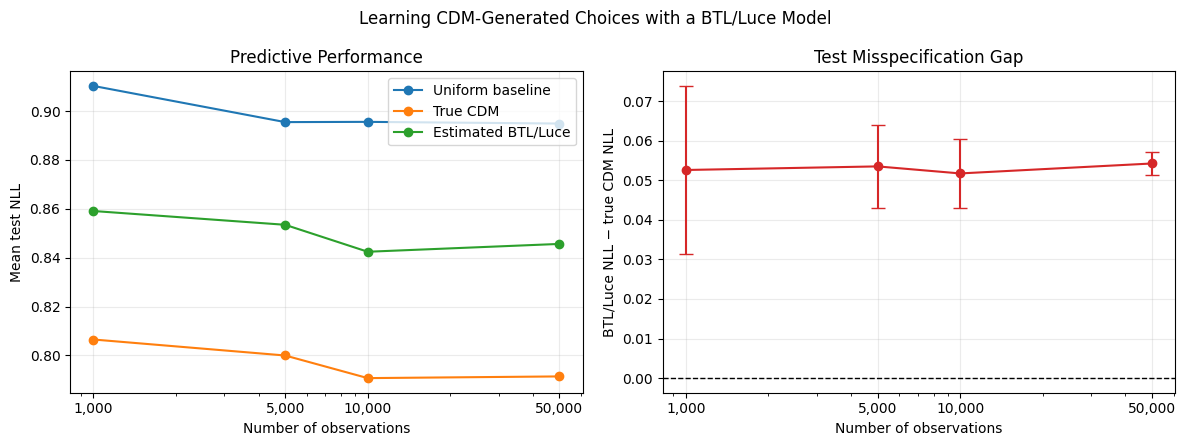

In [31]:
# Plot predictive NLL and the CDM-to-BTL misspecification gap.

observation_counts = (
    cdm_to_btl_summary[
        "Number of observations"
    ].to_numpy()
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
)

axes[0].plot(
    observation_counts,
    cdm_to_btl_summary[
        "Mean_uniform_test_NLL"
    ],
    marker="o",
    label="Uniform baseline",
)

axes[0].plot(
    observation_counts,
    cdm_to_btl_summary[
        "Mean_true_CDM_test_NLL"
    ],
    marker="o",
    label="True CDM",
)

axes[0].plot(
    observation_counts,
    cdm_to_btl_summary[
        "Mean_BTL_test_NLL"
    ],
    marker="o",
    label="Estimated BTL/Luce",
)

axes[0].set_xscale("log")
axes[0].set_xticks(observation_counts)
axes[0].set_xticklabels(
    [
        f"{count:,}"
        for count in observation_counts
    ]
)
axes[0].set_xlabel("Number of observations")
axes[0].set_ylabel("Mean test NLL")
axes[0].set_title("Predictive Performance")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].errorbar(
    observation_counts,
    cdm_to_btl_summary[
        "Mean_test_misspecification_gap"
    ],
    yerr=cdm_to_btl_summary[
        "Test_misspecification_gap_std"
    ],
    marker="o",
    capsize=5,
    color="tab:red",
)

axes[1].axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1,
)

axes[1].set_xscale("log")
axes[1].set_xticks(observation_counts)
axes[1].set_xticklabels(
    [
        f"{count:,}"
        for count in observation_counts
    ]
)
axes[1].set_xlabel("Number of observations")
axes[1].set_ylabel(
    "BTL/Luce NLL − true CDM NLL"
)
axes[1].set_title("Test Misspecification Gap")
axes[1].grid(alpha=0.25)

figure.suptitle(
    "Learning CDM-Generated Choices with a BTL/Luce Model"
)

figure.tight_layout()

figure.savefig(
    CDM_BTL_FIGURE_DIRECTORY
    / "02_misspecification_gap_vs_observations.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()

In [32]:
# Export the CDM-to-BTL observation-scaling summary as a LaTeX table.

CDM_BTL_TABLE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "tables"
    / "experiments"
    / "context_dependent_model"
    / "cdm_btl"
)

CDM_BTL_TABLE_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

cdm_to_btl_overleaf_table = (
    cdm_to_btl_summary[
        [
            "Number of observations",
            "Mean_uniform_test_NLL",
            "Mean_true_CDM_test_NLL",
            "Mean_BTL_test_NLL",
            "Mean_test_misspecification_gap",
            "Test_misspecification_gap_std",
        ]
    ]
    .rename(
        columns={
            "Number of observations": "Observations",
            "Mean_uniform_test_NLL": "Uniform NLL",
            "Mean_true_CDM_test_NLL": "True CDM NLL",
            "Mean_BTL_test_NLL": "BTL/Luce NLL",
            "Mean_test_misspecification_gap": "Gap",
            "Test_misspecification_gap_std": "Gap SD",
        }
    )
)

cdm_to_btl_overleaf_table.to_latex(
    CDM_BTL_TABLE_DIRECTORY
    / "01_observation_scaling_summary.tex",
    index=False,
    float_format="%.4f",
    caption=(
        "Predictive performance of a BTL/Luce model "
        "fitted to CDM-generated choice data."
    ),
    label="tab:cdm-btl-observation-scaling",
    position="htbp",
)

cdm_to_btl_overleaf_table

,Observations,Uniform NLL,True CDM NLL,BTL/Luce NLL,Gap,Gap SD
0,1000,0.910274,0.806516,0.859095,0.052579,0.021232
1,5000,0.895474,0.799971,0.853457,0.053486,0.010397
2,10000,0.895576,0.790716,0.842425,0.051709,0.008628
3,50000,0.894886,0.791410,0.845630,0.054220,0.002992


In [33]:
# Define the interaction strengths and generate one common base CDM matrix.

CONTEXT_INTERACTION_SCALES = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.00,
]

CONTEXT_STRENGTH_OBSERVATIONS = 50_000

context_strength_base_interactions = (
    generate_cdm_parameters(
        number_of_items=NUMBER_OF_ITEMS,
        parameter_scale=1.0,
        random_seed=SEED,
        device=DEVICE,
        dtype=DTYPE,
    )
)

context_strength_settings = pd.DataFrame(
    {
        "Setting": [
            "Interaction scales",
            "Number of observations",
            "Runs per scale",
            "Total runs",
        ],
        "Value": [
            str(CONTEXT_INTERACTION_SCALES),
            CONTEXT_STRENGTH_OBSERVATIONS,
            len(CDM_TO_BTL_SEEDS),
            (
                len(CONTEXT_INTERACTION_SCALES)
                * len(CDM_TO_BTL_SEEDS)
            ),
        ],
    }
)

context_strength_settings

,Setting,Value
0,Interaction scales,"[0.0, 0.25, 0.5, 0.75, 1.0]"
1,Number of observations,50000
2,Runs per scale,10
3,Total runs,50


In [34]:
# Run one small context-strength trial before starting the full experiment.

context_strength_smoke_test = pd.DataFrame(
    run_cdm_to_btl_context_strength_experiment(
        base_interactions=(
            context_strength_base_interactions
        ),
        interaction_scales=[0.50],
        number_of_observations=1_000,
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=[SEED],
        train_fraction=TRAIN_FRACTION,
        choix_alpha=0.0,
        maximum_iterations=1_000,
        tolerance=1e-8,
    )
)

context_strength_smoke_test


Interaction scale: 0.50
Running 1/1: observations=1,000, run=1
All CDM-to-BTL trials completed.
All context-strength trials completed.


,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,...,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds),Interaction scale
0,5,1000,1,20260831,20260832,800,200,19,4,0.8974,...,0.783793,0.825542,0.84635,0.876249,0.062557,0.050707,0.05105,0.043959,0.013707,0.5


In [35]:
# Run repeated CDM-to-BTL experiments across increasing interaction strengths.

context_strength_results = pd.DataFrame(
    run_cdm_to_btl_context_strength_experiment(
        base_interactions=(
            context_strength_base_interactions
        ),
        interaction_scales=(
            CONTEXT_INTERACTION_SCALES
        ),
        number_of_observations=(
            CONTEXT_STRENGTH_OBSERVATIONS
        ),
        choice_set_sizes=CHOICE_SET_SIZES,
        random_seeds=CDM_TO_BTL_SEEDS,
        train_fraction=TRAIN_FRACTION,
        choix_alpha=0.0,
        maximum_iterations=1_000,
        tolerance=1e-8,
    )
)

context_strength_results


Interaction scale: 0.00
Running 1/10: observations=50,000, run=1
Running 2/10: observations=50,000, run=2
Running 3/10: observations=50,000, run=3
Running 4/10: observations=50,000, run=4
Running 5/10: observations=50,000, run=5
Running 6/10: observations=50,000, run=6
Running 7/10: observations=50,000, run=7
Running 8/10: observations=50,000, run=8
Running 9/10: observations=50,000, run=9
Running 10/10: observations=50,000, run=10
All CDM-to-BTL trials completed.

Interaction scale: 0.25
Running 1/10: observations=50,000, run=1
Running 2/10: observations=50,000, run=2
Running 3/10: observations=50,000, run=3
Running 4/10: observations=50,000, run=4
Running 5/10: observations=50,000, run=5
Running 6/10: observations=50,000, run=6
Running 7/10: observations=50,000, run=7
Running 8/10: observations=50,000, run=8
Running 9/10: observations=50,000, run=9
Running 10/10: observations=50,000, run=10
All CDM-to-BTL trials completed.

Interaction scale: 0.50
Running 1/10: observations=50,000, 

,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,...,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds),Interaction scale
0,5,50000,1,20260831,20260832,40000,10000,19,4,0.896579,...,0.896579,0.898313,0.896572,0.898334,-0.000008,0.000021,0.000008,-0.000021,0.295921,0.00
1,5,50000,2,20260832,20260833,40000,10000,19,4,0.895738,...,0.895738,0.891257,0.895657,0.891291,-0.000081,0.000033,0.000081,-0.000033,0.267538,0.00
2,5,50000,3,20260833,20260834,40000,10000,19,4,0.897421,...,0.897421,0.893852,0.897400,0.893865,-0.000021,0.000012,0.000021,-0.000012,0.265841,0.00
3,5,50000,4,20260834,20260835,40000,10000,19,4,0.895474,...,0.895474,0.897704,0.895448,0.897775,-0.000027,0.000071,0.000027,-0.000071,0.375160,0.00
4,5,50000,5,20260835,20260836,40000,10000,19,4,0.895910,...,0.895910,0.897542,0.895851,0.897587,-0.000059,0.000045,0.000059,-0.000045,0.280819,0.00
5,5,50000,6,20260836,20260837,40000,10000,19,4,0.895201,...,0.895201,0.895799,0.895130,0.895909,-0.000071,0.000110,0.000071,-0.000110,0.267777,0.00
6,5,50000,7,20260837,20260838,40000,10000,19,4,0.896893,...,0.896893,0.892312,0.896871,0.892273,-0.000023,-0.000038,0.000023,0.000038,0.269439,0.00
7,5,50000,8,20260838,20260839,40000,10000,19,4,0.895565,...,0.895565,0.893366,0.895406,0.893382,-0.000160,0.000016,0.000160,-0.000016,0.273593,0.00
8,5,50000,9,20260839,20260840,40000,10000,19,4,0.894927,...,0.894927,0.894947,0.894891,0.895058,-0.000036,0.000111,0.000036,-0.000111,0.270856,0.00
9,5,50000,10,20260840,20260841,40000,10000,19,4,0.894238,...,0.894238,0.893771,0.894131,0.893656,-0.000106,-0.000115,0.000106,0.000115,0.267439,0.00


In [36]:
# Summarise the repeated experiments for each CDM interaction strength.

context_strength_summary = (
    context_strength_results.groupby(
        "Interaction scale",
        as_index=False,
    )
    .agg(
        Runs=("Run", "count"),
        Mean_uniform_test_NLL=(
            "Uniform test NLL",
            "mean",
        ),
        Mean_true_CDM_test_NLL=(
            "True CDM test NLL",
            "mean",
        ),
        Mean_BTL_test_NLL=(
            "BTL/Luce test NLL",
            "mean",
        ),
        Mean_training_misspecification_gap=(
            "Training misspecification gap",
            "mean",
        ),
        Mean_test_misspecification_gap=(
            "Test misspecification gap",
            "mean",
        ),
        Test_misspecification_gap_std=(
            "Test misspecification gap",
            "std",
        ),
        Mean_BTL_test_improvement=(
            "BTL test improvement over uniform",
            "mean",
        ),
        Mean_runtime=(
            "BTL runtime (seconds)",
            "mean",
        ),
    )
)

context_strength_summary.style.format(
    {
        "Interaction scale": "{:.2f}",
        "Runs": "{:,}",
        "Mean_uniform_test_NLL": "{:.4f}",
        "Mean_true_CDM_test_NLL": "{:.4f}",
        "Mean_BTL_test_NLL": "{:.4f}",
        "Mean_training_misspecification_gap": "{:.4f}",
        "Mean_test_misspecification_gap": "{:.4f}",
        "Test_misspecification_gap_std": "{:.4f}",
        "Mean_BTL_test_improvement": "{:.4f}",
        "Mean_runtime": "{:.4f}",
    }
)

,Interaction scale,Runs,Mean_uniform_test_NLL,Mean_true_CDM_test_NLL,Mean_BTL_test_NLL,Mean_training_misspecification_gap,Mean_test_misspecification_gap,Test_misspecification_gap_std,Mean_BTL_test_improvement,Mean_runtime
0,0.00,10,0.8949,0.8949,0.8949,-0.0001,0.0000,0.0001,-0.0000,0.2834
1,0.25,10,0.8949,0.8644,0.8793,0.0152,0.0148,0.0014,0.0156,0.4983
2,0.50,10,0.8949,0.7914,0.8456,0.0549,0.0542,0.0030,0.0493,0.6240
3,0.75,10,0.8949,0.7056,0.8091,0.1046,0.1035,0.0056,0.0858,0.7235
4,1.00,10,0.8949,0.6237,0.7773,0.1560,0.1536,0.0063,0.1176,0.8574


In [39]:
# Generate a common base CDM interaction matrix for the ten-item experiment.

TEN_ITEM_COUNT = 10

ten_item_base_interactions = (
    generate_cdm_parameters(
        number_of_items=TEN_ITEM_COUNT,
        parameter_scale=1.0,
        random_seed=SEED,
        device=DEVICE,
        dtype=DTYPE,
    )
)

ten_item_base_interactions.shape

torch.Size([10, 10])

In [40]:
# Run one ten-item trial to verify the context-strength experiment.

ten_item_context_strength_smoke_test = (
    pd.DataFrame(
        run_cdm_to_btl_context_strength_experiment(
            base_interactions=(
                ten_item_base_interactions
            ),
            interaction_scales=[0.50],
            number_of_observations=5_000,
            choice_set_sizes=CHOICE_SET_SIZES,
            random_seeds=[
                CDM_TO_BTL_SEEDS[0]
            ],
            train_fraction=TRAIN_FRACTION,
            choix_alpha=0.0,
            maximum_iterations=1_000,
            tolerance=1e-8,
        )
    )
)

ten_item_context_strength_smoke_test


Interaction scale: 0.50
Running 1/1: observations=5,000, run=1
All CDM-to-BTL trials completed.
All context-strength trials completed.


,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,...,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds),Interaction scale
0,10,5000,1,20260831,20260832,4000,1000,89,9,0.895576,...,0.822154,0.846903,0.880222,0.892819,0.058067,0.045916,0.015354,0.003466,0.140691,0.5


In [41]:
# Run the full context-strength experiment with ten items.

ten_item_context_strength_results = (
    pd.DataFrame(
        run_cdm_to_btl_context_strength_experiment(
            base_interactions=(
                ten_item_base_interactions
            ),
            interaction_scales=(
                CONTEXT_INTERACTION_SCALES
            ),
            number_of_observations=(
                CONTEXT_STRENGTH_OBSERVATIONS
            ),
            choice_set_sizes=CHOICE_SET_SIZES,
            random_seeds=CDM_TO_BTL_SEEDS,
            train_fraction=TRAIN_FRACTION,
            choix_alpha=0.0,
            maximum_iterations=1_000,
            tolerance=1e-8,
        )
    )
)

ten_item_context_strength_results


Interaction scale: 0.00
Running 1/10: observations=50,000, run=1
Running 2/10: observations=50,000, run=2
Running 3/10: observations=50,000, run=3
Running 4/10: observations=50,000, run=4
Running 5/10: observations=50,000, run=5
Running 6/10: observations=50,000, run=6
Running 7/10: observations=50,000, run=7
Running 8/10: observations=50,000, run=8
Running 9/10: observations=50,000, run=9
Running 10/10: observations=50,000, run=10
All CDM-to-BTL trials completed.

Interaction scale: 0.25
Running 1/10: observations=50,000, run=1
Running 2/10: observations=50,000, run=2
Running 3/10: observations=50,000, run=3
Running 4/10: observations=50,000, run=4
Running 5/10: observations=50,000, run=5
Running 6/10: observations=50,000, run=6
Running 7/10: observations=50,000, run=7
Running 8/10: observations=50,000, run=8
Running 9/10: observations=50,000, run=9
Running 10/10: observations=50,000, run=10
All CDM-to-BTL trials completed.

Interaction scale: 0.50
Running 1/10: observations=50,000, 

,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,...,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds),Interaction scale
0,10,50000,1,20260831,20260832,40000,10000,89,9,0.896579,...,0.896579,0.898313,0.896430,0.898436,-0.000149,0.000123,0.000149,-0.000123,0.403536,0.00
1,10,50000,2,20260832,20260833,40000,10000,89,9,0.895738,...,0.895738,0.891257,0.895565,0.891568,-0.000173,0.000311,0.000173,-0.000311,0.319125,0.00
2,10,50000,3,20260833,20260834,40000,10000,89,9,0.897421,...,0.897421,0.893852,0.897362,0.893726,-0.000059,-0.000127,0.000059,0.000127,0.321271,0.00
3,10,50000,4,20260834,20260835,40000,10000,89,9,0.895474,...,0.895474,0.897704,0.895362,0.897853,-0.000112,0.000148,0.000112,-0.000148,0.271961,0.00
4,10,50000,5,20260835,20260836,40000,10000,89,9,0.895910,...,0.895910,0.897542,0.895837,0.897566,-0.000073,0.000024,0.000073,-0.000024,0.269763,0.00
5,10,50000,6,20260836,20260837,40000,10000,89,9,0.895201,...,0.895201,0.895799,0.895144,0.895863,-0.000057,0.000064,0.000057,-0.000064,0.326017,0.00
6,10,50000,7,20260837,20260838,40000,10000,89,9,0.896893,...,0.896893,0.892312,0.896852,0.892293,-0.000041,-0.000018,0.000041,0.000018,0.277968,0.00
7,10,50000,8,20260838,20260839,40000,10000,89,9,0.895565,...,0.895565,0.893366,0.895369,0.893361,-0.000196,-0.000005,0.000196,0.000005,0.322954,0.00
8,10,50000,9,20260839,20260840,40000,10000,89,9,0.894927,...,0.894927,0.894947,0.894862,0.894973,-0.000065,0.000026,0.000065,-0.000026,0.322222,0.00
9,10,50000,10,20260840,20260841,40000,10000,89,9,0.894238,...,0.894238,0.893771,0.894180,0.893818,-0.000057,0.000047,0.000057,-0.000047,0.322062,0.00


In [42]:
# Combine and summarise the five-item and ten-item context-strength results.

combined_context_strength_results = pd.concat(
    [
        context_strength_results,
        ten_item_context_strength_results,
    ],
    ignore_index=True,
)

combined_context_strength_summary = (
    combined_context_strength_results.groupby(
        [
            "Number of items",
            "Interaction scale",
        ],
        as_index=False,
    )
    .agg(
        Runs=("Run", "count"),
        Mean_uniform_test_NLL=(
            "Uniform test NLL",
            "mean",
        ),
        Mean_true_CDM_test_NLL=(
            "True CDM test NLL",
            "mean",
        ),
        Mean_BTL_test_NLL=(
            "BTL/Luce test NLL",
            "mean",
        ),
        Mean_test_misspecification_gap=(
            "Test misspecification gap",
            "mean",
        ),
        Test_misspecification_gap_std=(
            "Test misspecification gap",
            "std",
        ),
        Mean_BTL_test_improvement=(
            "BTL test improvement over uniform",
            "mean",
        ),
        Mean_runtime=(
            "BTL runtime (seconds)",
            "mean",
        ),
    )
)

combined_context_strength_summary.style.format(
    {
        "Number of items": "{:,}",
        "Interaction scale": "{:.2f}",
        "Runs": "{:,}",
        "Mean_uniform_test_NLL": "{:.4f}",
        "Mean_true_CDM_test_NLL": "{:.4f}",
        "Mean_BTL_test_NLL": "{:.4f}",
        "Mean_test_misspecification_gap": "{:.4f}",
        "Test_misspecification_gap_std": "{:.4f}",
        "Mean_BTL_test_improvement": "{:.4f}",
        "Mean_runtime": "{:.4f}",
    }
)

,Number of items,Interaction scale,Runs,Mean_uniform_test_NLL,Mean_true_CDM_test_NLL,Mean_BTL_test_NLL,Mean_test_misspecification_gap,Test_misspecification_gap_std,Mean_BTL_test_improvement,Mean_runtime
0,5,0.00,10,0.8949,0.8949,0.8949,0.0000,0.0001,-0.0000,0.2834
1,5,0.25,10,0.8949,0.8644,0.8793,0.0148,0.0014,0.0156,0.4983
2,5,0.50,10,0.8949,0.7914,0.8456,0.0542,0.0030,0.0493,0.6240
3,5,0.75,10,0.8949,0.7056,0.8091,0.1035,0.0056,0.0858,0.7235
4,5,1.00,10,0.8949,0.6237,0.7773,0.1536,0.0063,0.1176,0.8574
5,10,0.00,10,0.8949,0.8949,0.8949,0.0001,0.0001,-0.0001,0.3157
6,10,0.25,10,0.8949,0.8734,0.8909,0.0175,0.0017,0.0040,0.4691
7,10,0.50,10,0.8949,0.8226,0.8823,0.0597,0.0034,0.0126,0.5222
8,10,0.75,10,0.8949,0.7559,0.8719,0.1160,0.0041,0.0230,0.6404
9,10,1.00,10,0.8949,0.6889,0.8617,0.1728,0.0052,0.0332,0.6594


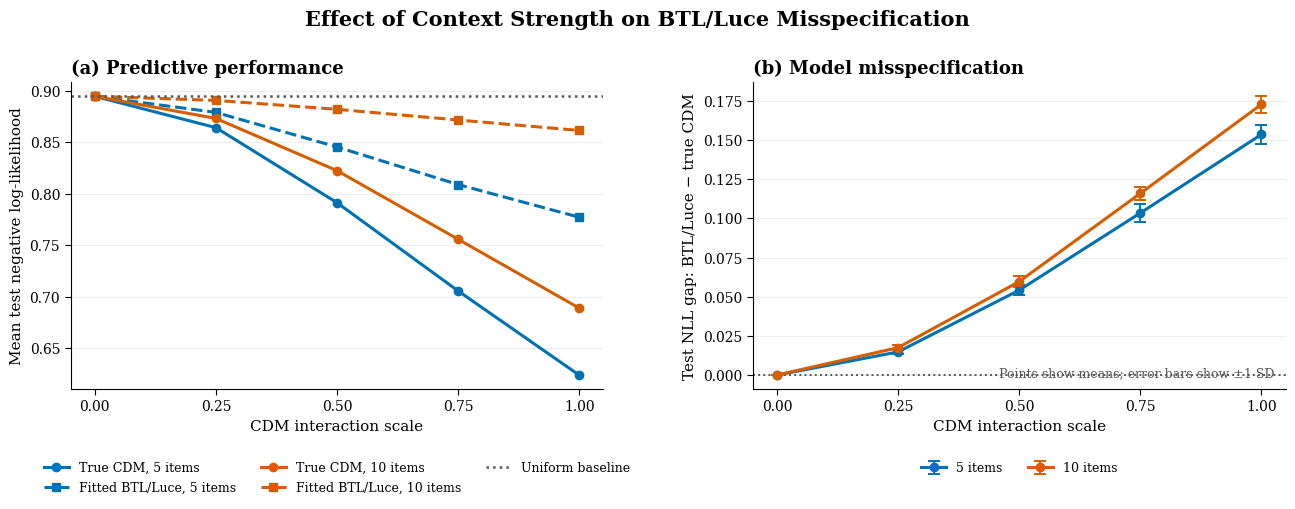

In [50]:
# Create a publication-quality context-strength comparison figure.

item_colours = {
    5: "#0072B2",
    10: "#D55E00",
}

with plt.rc_context(
    {
        "font.family": "serif",
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "legend.fontsize": 9,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
):
    figure, axes = plt.subplots(
        1,
        2,
        figsize=(13.5, 5.2),
        facecolor="white",
    )

    for number_of_items in [5, 10]:
        item_summary = (
            combined_context_strength_summary.loc[
                combined_context_strength_summary[
                    "Number of items"
                ].eq(number_of_items)
            ]
        )

        interaction_scales = item_summary[
            "Interaction scale"
        ]

        axes[0].plot(
            interaction_scales,
            item_summary[
                "Mean_true_CDM_test_NLL"
            ],
            marker="o",
            markersize=6,
            linewidth=2.2,
            color=item_colours[number_of_items],
            label=(
                f"True CDM, "
                f"{number_of_items} items"
            ),
        )

        axes[0].plot(
            interaction_scales,
            item_summary[
                "Mean_BTL_test_NLL"
            ],
            marker="s",
            markersize=6,
            linewidth=2.2,
            linestyle="--",
            color=item_colours[number_of_items],
            label=(
                f"Fitted BTL/Luce, "
                f"{number_of_items} items"
            ),
        )

        axes[1].errorbar(
            interaction_scales,
            item_summary[
                "Mean_test_misspecification_gap"
            ],
            yerr=item_summary[
                "Test_misspecification_gap_std"
            ],
            marker="o",
            markersize=6,
            linewidth=2.2,
            elinewidth=1.4,
            capsize=4,
            capthick=1.4,
            color=item_colours[number_of_items],
            label=f"{number_of_items} items",
        )

    uniform_test_nll = (
        combined_context_strength_summary[
            "Mean_uniform_test_NLL"
        ].mean()
    )

    axes[0].axhline(
        uniform_test_nll,
        color="#555555",
        linestyle=":",
        linewidth=1.8,
        label="Uniform baseline",
    )

    for axis in axes:
        axis.set_xticks(
            CONTEXT_INTERACTION_SCALES
        )

        axis.set_xticklabels(
            [
                f"{scale:.2f}"
                for scale
                in CONTEXT_INTERACTION_SCALES
            ]
        )

        axis.grid(
            axis="y",
            alpha=0.22,
            linewidth=0.8,
        )

        axis.tick_params(
            direction="out",
            length=4,
        )

        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    axes[0].set_xlabel(
        "CDM interaction scale"
    )
    axes[0].set_ylabel(
        "Mean test negative log-likelihood"
    )
    axes[0].set_title(
        "(a) Predictive performance",
        loc="left",
        fontweight="semibold",
    )

    axes[0].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=3,
        frameon=False,
    )

    axes[1].axhline(
        0.0,
        color="#555555",
        linestyle=":",
        linewidth=1.4,
    )

    axes[1].set_xlabel(
        "CDM interaction scale"
    )
    axes[1].set_ylabel(
        "Test NLL gap: BTL/Luce − true CDM"
    )
    axes[1].set_title(
        "(b) Model misspecification",
        loc="left",
        fontweight="semibold",
    )

    axes[1].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
    )

    axes[1].text(
        0.98,
        0.04,
        "Points show means; error bars show ±1 SD",
        transform=axes[1].transAxes,
        horizontalalignment="right",
        fontsize=9,
        color="#555555",
    )

    figure.suptitle(
        "Effect of Context Strength on BTL/Luce Misspecification",
        fontsize=15,
        fontweight="semibold",
        y=0.98,
    )

    figure.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.84,
        bottom=0.25,
        wspace=0.28,
    )

    figure.savefig(
        CDM_BTL_FIGURE_DIRECTORY
        / "03_context_strength_comparison.pdf",
        bbox_inches="tight",
    )

    plt.show()

In [44]:
# Export the combined context-strength summary as a LaTeX table.

context_strength_overleaf_table = (
    combined_context_strength_summary[
        [
            "Number of items",
            "Interaction scale",
            "Mean_true_CDM_test_NLL",
            "Mean_BTL_test_NLL",
            "Mean_test_misspecification_gap",
            "Test_misspecification_gap_std",
        ]
    ]
    .rename(
        columns={
            "Number of items": "Items",
            "Interaction scale": "Scale",
            "Mean_true_CDM_test_NLL": (
                "True CDM NLL"
            ),
            "Mean_BTL_test_NLL": (
                "BTL/Luce NLL"
            ),
            "Mean_test_misspecification_gap": (
                "Gap"
            ),
            "Test_misspecification_gap_std": (
                "Gap SD"
            ),
        }
    )
)

context_strength_overleaf_table.to_latex(
    CDM_BTL_TABLE_DIRECTORY
    / "02_context_strength_summary.tex",
    index=False,
    float_format="%.4f",
    caption=(
        "Effect of CDM interaction strength on "
        "BTL/Luce model misspecification."
    ),
    label="tab:cdm-btl-context-strength",
    position="htbp",
)

context_strength_overleaf_table

,Items,Scale,True CDM NLL,BTL/Luce NLL,Gap,Gap SD
0,5,0.00,0.894886,0.894913,0.000027,0.000068
1,5,0.25,0.864439,0.879253,0.014814,0.001445
2,5,0.50,0.791410,0.845630,0.054220,0.002992
3,5,0.75,0.705603,0.809072,0.103469,0.005564
4,5,1.00,0.623683,0.777301,0.153618,0.006294
5,10,0.00,0.894886,0.894946,0.000059,0.000117
6,10,0.25,0.873419,0.890931,0.017511,0.001664
7,10,0.50,0.822585,0.882277,0.059692,0.003418
8,10,0.75,0.755874,0.871862,0.115987,0.004098
9,10,1.00,0.688885,0.861714,0.172830,0.005177


In [45]:
# Construct the ten-item CDM matrix using the baseline interaction scale.

OBSERVATION_SCALING_INTERACTION_SCALE = 0.50

ten_item_true_interactions = (
    OBSERVATION_SCALING_INTERACTION_SCALE
    * ten_item_base_interactions
)

ten_item_true_interactions.shape

torch.Size([10, 10])

In [46]:
# Run the observation-scaling experiment with ten CDM items.

ten_item_observation_scaling_results = (
    pd.DataFrame(
        run_cdm_to_btl_experiment(
            true_interactions=(
                ten_item_true_interactions
            ),
            observation_counts=(
                CDM_TO_BTL_OBSERVATION_COUNTS
            ),
            choice_set_sizes=CHOICE_SET_SIZES,
            random_seeds=CDM_TO_BTL_SEEDS,
            train_fraction=TRAIN_FRACTION,
            choix_alpha=0.0,
            maximum_iterations=1_000,
            tolerance=1e-8,
        )
    )
)

ten_item_observation_scaling_results

Running 1/40: observations=1,000, run=1
Running 2/40: observations=1,000, run=2
Running 3/40: observations=1,000, run=3
Running 4/40: observations=1,000, run=4
Running 5/40: observations=1,000, run=5
Running 6/40: observations=1,000, run=6
Running 7/40: observations=1,000, run=7
Running 8/40: observations=1,000, run=8
Running 9/40: observations=1,000, run=9
Running 10/40: observations=1,000, run=10
Running 11/40: observations=5,000, run=1
Running 12/40: observations=5,000, run=2
Running 13/40: observations=5,000, run=3
Running 14/40: observations=5,000, run=4
Running 15/40: observations=5,000, run=5
Running 16/40: observations=5,000, run=6
Running 17/40: observations=5,000, run=7
Running 18/40: observations=5,000, run=8
Running 19/40: observations=5,000, run=9
Running 20/40: observations=5,000, run=10
Running 21/40: observations=10,000, run=1
Running 22/40: observations=10,000, run=2
Running 23/40: observations=10,000, run=3
Running 24/40: observations=10,000, run=4
Running 25/40: obse

,Number of items,Number of observations,Run,Random seed,Split seed,Training observations,Test observations,Number of free CDM parameters,Number of free BTL parameters,Uniform training NLL,Uniform test NLL,True CDM training NLL,True CDM test NLL,BTL/Luce training NLL,BTL/Luce test NLL,Training misspecification gap,Test misspecification gap,BTL training improvement over uniform,BTL test improvement over uniform,BTL runtime (seconds)
0,10,1000,1,20260831,20260832,800,200,89,9,0.897400,0.920208,0.815014,0.884078,0.885135,0.908646,0.070122,0.024568,0.012265,0.011562,0.031438
1,10,1000,2,20260832,20260833,800,200,89,9,0.901962,0.899934,0.839211,0.857705,0.891161,0.878345,0.051950,0.020640,0.010800,0.021589,0.013413
2,10,1000,3,20260833,20260834,800,200,89,9,0.893346,0.914126,0.809604,0.862776,0.868893,0.913306,0.059289,0.050530,0.024453,0.000819,0.011483
3,10,1000,4,20260834,20260835,800,200,89,9,0.897400,0.920208,0.826400,0.852259,0.876428,0.919108,0.050028,0.066849,0.020972,0.001099,0.012125
4,10,1000,5,20260835,20260836,800,200,89,9,0.894866,0.895880,0.825950,0.820031,0.874450,0.863096,0.048500,0.043065,0.020416,0.032784,0.047644
5,10,1000,6,20260836,20260837,800,200,89,9,0.894359,0.916153,0.817019,0.822477,0.878934,0.894685,0.061915,0.072208,0.015425,0.021468,0.015546
6,10,1000,7,20260837,20260838,800,200,89,9,0.882702,0.914126,0.802421,0.861243,0.862922,0.891414,0.060500,0.030171,0.019780,0.022712,0.012909
7,10,1000,8,20260838,20260839,800,200,89,9,0.901962,0.895880,0.822990,0.857092,0.884798,0.890952,0.061808,0.033860,0.017164,0.004928,0.014561
8,10,1000,9,20260839,20260840,800,200,89,9,0.894359,0.903989,0.825536,0.812871,0.876133,0.890719,0.050596,0.077848,0.018227,0.013271,0.012821
9,10,1000,10,20260840,20260841,800,200,89,9,0.891825,0.922235,0.810072,0.853107,0.872405,0.935062,0.062333,0.081956,0.019420,-0.012827,0.016487


In [47]:
# Combine and summarise the observation-scaling results for both item counts.

combined_observation_scaling_results = pd.concat(
    [
        cdm_to_btl_results,
        ten_item_observation_scaling_results,
    ],
    ignore_index=True,
)

combined_observation_scaling_summary = (
    combined_observation_scaling_results.groupby(
        [
            "Number of items",
            "Number of observations",
        ],
        as_index=False,
    )
    .agg(
        Runs=("Run", "count"),
        Mean_uniform_test_NLL=(
            "Uniform test NLL",
            "mean",
        ),
        Mean_true_CDM_test_NLL=(
            "True CDM test NLL",
            "mean",
        ),
        Mean_BTL_test_NLL=(
            "BTL/Luce test NLL",
            "mean",
        ),
        Mean_training_misspecification_gap=(
            "Training misspecification gap",
            "mean",
        ),
        Mean_test_misspecification_gap=(
            "Test misspecification gap",
            "mean",
        ),
        Test_misspecification_gap_std=(
            "Test misspecification gap",
            "std",
        ),
        Mean_BTL_test_improvement=(
            "BTL test improvement over uniform",
            "mean",
        ),
        Mean_runtime=(
            "BTL runtime (seconds)",
            "mean",
        ),
    )
)

combined_observation_scaling_summary.style.format(
    {
        "Number of items": "{:,}",
        "Number of observations": "{:,}",
        "Runs": "{:,}",
        "Mean_uniform_test_NLL": "{:.4f}",
        "Mean_true_CDM_test_NLL": "{:.4f}",
        "Mean_BTL_test_NLL": "{:.4f}",
        "Mean_training_misspecification_gap": "{:.4f}",
        "Mean_test_misspecification_gap": "{:.4f}",
        "Test_misspecification_gap_std": "{:.4f}",
        "Mean_BTL_test_improvement": "{:.4f}",
        "Mean_runtime": "{:.4f}",
    }
)

,Number of items,Number of observations,Runs,Mean_uniform_test_NLL,Mean_true_CDM_test_NLL,Mean_BTL_test_NLL,Mean_training_misspecification_gap,Mean_test_misspecification_gap,Test_misspecification_gap_std,Mean_BTL_test_improvement,Mean_runtime
0,5,"1,000",10,0.9103,0.8065,0.8591,0.0526,0.0526,0.0212,0.0512,0.0148
1,5,"5,000",10,0.8955,0.8000,0.8535,0.0563,0.0535,0.0104,0.0420,0.0765
2,5,"10,000",10,0.8956,0.7907,0.8424,0.0563,0.0517,0.0086,0.0532,0.1401
3,5,"50,000",10,0.8949,0.7914,0.8456,0.0549,0.0542,0.0030,0.0493,0.6360
4,10,"1,000",10,0.9103,0.8484,0.8985,0.0577,0.0502,0.0231,0.0117,0.0188
5,10,"5,000",10,0.8955,0.8274,0.8837,0.0606,0.0563,0.0124,0.0118,0.0566
6,10,"10,000",10,0.8956,0.8207,0.8845,0.0598,0.0638,0.0081,0.0111,0.1169
7,10,"50,000",10,0.8949,0.8226,0.8823,0.0600,0.0597,0.0034,0.0126,0.5299


combined observation scaling plot

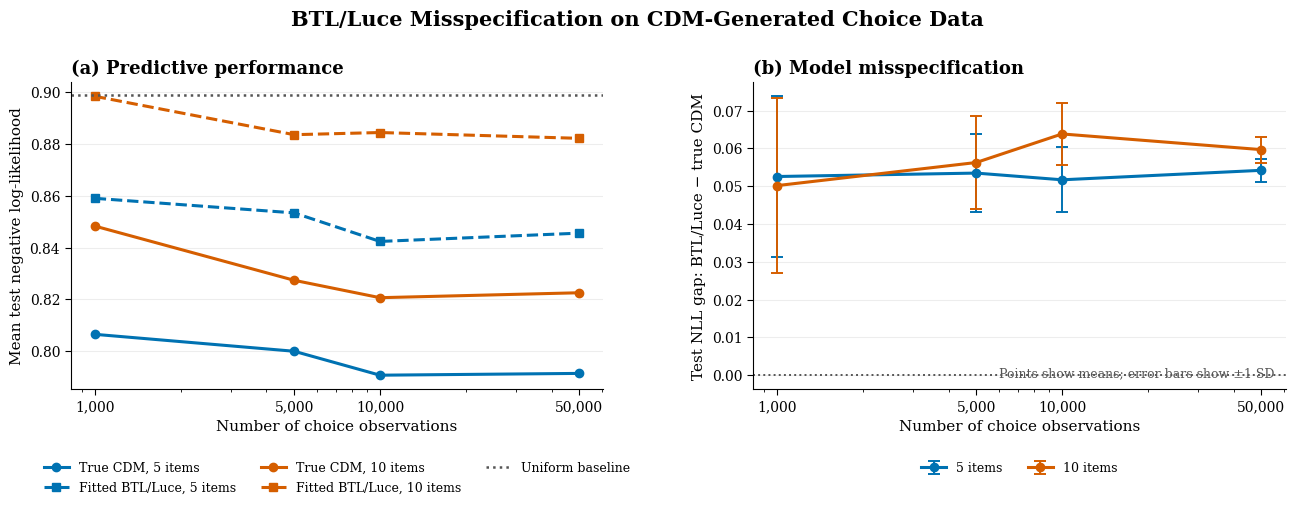

In [49]:
# plot

item_colours = {
    5: "#0072B2",
    10: "#D55E00",
}

with plt.rc_context(
    {
        "font.family": "serif",
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "legend.fontsize": 9,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
):
    figure, axes = plt.subplots(
        1,
        2,
        figsize=(13.5, 5.2),
        facecolor="white",
    )

    for number_of_items in [5, 10]:
        item_summary = (
            combined_observation_scaling_summary.loc[
                combined_observation_scaling_summary[
                    "Number of items"
                ].eq(number_of_items)
            ]
        )

        observation_counts = item_summary[
            "Number of observations"
        ]

        axes[0].plot(
            observation_counts,
            item_summary[
                "Mean_true_CDM_test_NLL"
            ],
            marker="o",
            markersize=6,
            linewidth=2.2,
            color=item_colours[number_of_items],
            label=(
                f"True CDM, "
                f"{number_of_items} items"
            ),
        )

        axes[0].plot(
            observation_counts,
            item_summary[
                "Mean_BTL_test_NLL"
            ],
            marker="s",
            markersize=6,
            linewidth=2.2,
            linestyle="--",
            color=item_colours[number_of_items],
            label=(
                f"Fitted BTL/Luce, "
                f"{number_of_items} items"
            ),
        )

        axes[1].errorbar(
            observation_counts,
            item_summary[
                "Mean_test_misspecification_gap"
            ],
            yerr=item_summary[
                "Test_misspecification_gap_std"
            ],
            marker="o",
            markersize=6,
            linewidth=2.2,
            elinewidth=1.4,
            capsize=4,
            capthick=1.4,
            color=item_colours[number_of_items],
            label=f"{number_of_items} items",
        )

    uniform_test_nll = (
        combined_observation_scaling_summary[
            "Mean_uniform_test_NLL"
        ].mean()
    )

    axes[0].axhline(
        uniform_test_nll,
        color="#555555",
        linestyle=":",
        linewidth=1.8,
        label="Uniform baseline",
    )

    for axis in axes:
        axis.set_xscale("log")
        axis.set_xticks(
            CDM_TO_BTL_OBSERVATION_COUNTS
        )
        axis.set_xticklabels(
            [
                f"{count:,}"
                for count
                in CDM_TO_BTL_OBSERVATION_COUNTS
            ]
        )

        axis.grid(
            axis="y",
            alpha=0.22,
            linewidth=0.8,
        )

        axis.tick_params(
            direction="out",
            length=4,
        )

        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    axes[0].set_xlabel(
        "Number of choice observations"
    )
    axes[0].set_ylabel(
        "Mean test negative log-likelihood"
    )
    axes[0].set_title(
        "(a) Predictive performance",
        loc="left",
        fontweight="semibold",
    )

    axes[0].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=3,
        frameon=False,
    )

    axes[1].axhline(
        0.0,
        color="#555555",
        linestyle=":",
        linewidth=1.4,
    )

    axes[1].set_xlabel(
        "Number of choice observations"
    )
    axes[1].set_ylabel(
        "Test NLL gap: BTL/Luce − true CDM"
    )
    axes[1].set_title(
        "(b) Model misspecification",
        loc="left",
        fontweight="semibold",
    )

    axes[1].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
    )

    axes[1].text(
        0.98,
        0.04,
        "Points show means; error bars show ±1 SD",
        transform=axes[1].transAxes,
        horizontalalignment="right",
        fontsize=9,
        color="#555555",
    )

    figure.suptitle(
        "BTL/Luce Misspecification on CDM-Generated Choice Data",
        fontsize=15,
        fontweight="semibold",
        y=0.98,
    )

    figure.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.84,
        bottom=0.25,
        wspace=0.28,
    )

    figure.savefig(
        CDM_BTL_FIGURE_DIRECTORY
        / "02_misspecification_gap_vs_observations.pdf",
        bbox_inches="tight",
    )

    plt.show()

In [51]:
# Export the combined observation-scaling summary as a LaTeX table.

observation_scaling_overleaf_table = (
    combined_observation_scaling_summary[
        [
            "Number of items",
            "Number of observations",
            "Mean_true_CDM_test_NLL",
            "Mean_BTL_test_NLL",
            "Mean_test_misspecification_gap",
            "Test_misspecification_gap_std",
        ]
    ]
    .rename(
        columns={
            "Number of items": "Items",
            "Number of observations": (
                "Observations"
            ),
            "Mean_true_CDM_test_NLL": (
                "True CDM NLL"
            ),
            "Mean_BTL_test_NLL": (
                "BTL/Luce NLL"
            ),
            "Mean_test_misspecification_gap": (
                "Gap"
            ),
            "Test_misspecification_gap_std": (
                "Gap SD"
            ),
        }
    )
)

observation_scaling_overleaf_table.to_latex(
    CDM_BTL_TABLE_DIRECTORY
    / "01_observation_scaling_summary.tex",
    index=False,
    float_format="%.4f",
    caption=(
        "Test performance of BTL/Luce models "
        "fitted to CDM-generated data as the "
        "number of observations increases."
    ),
    label="tab:cdm-btl-observation-scaling",
    position="htbp",
)

observation_scaling_overleaf_table

,Items,Observations,True CDM NLL,BTL/Luce NLL,Gap,Gap SD
0,5,1000,0.806516,0.859095,0.052579,0.021232
1,5,5000,0.799971,0.853457,0.053486,0.010397
2,5,10000,0.790716,0.842425,0.051709,0.008628
3,5,50000,0.791410,0.845630,0.054220,0.002992
4,10,1000,0.848364,0.898533,0.050169,0.023056
5,10,5000,0.827402,0.883688,0.056287,0.012380
6,10,10000,0.820676,0.884522,0.063847,0.008122
7,10,50000,0.822585,0.882277,0.059692,0.003418
